In [13]:
import pandas as pd, glob, os
syn = {os.path.basename(p)[:-4]: pd.read_csv(p) for p in sorted(glob.glob("data/synthetic/*.csv"))}
for name, df in syn.items():
    print(f"{name:40s} {len(df):>8,} rows  {df.shape[1]:>3} cols")

dim_commodity                                   2 rows    4 cols
dim_country                                     6 rows    7 cols
dim_plot                                    7,826 rows   12 cols
dim_supplier                                   53 rows    8 cols
fact_audits                                 2,368 rows    7 cols
fact_batch_plot_screening                  80,651 rows   10 cols
fact_compliance_cost_monthly                  350 rows    5 cols
fact_deforestation_alerts                   6,272 rows   10 cols
fact_plot_geodata_submissions              53,111 rows   16 cols
fact_risk_cases                             1,393 rows   13 cols
fact_shipment_batches                      53,078 rows   34 cols
fact_supplier_data_requests                 1,592 rows    5 cols
fact_supplier_monthly_scorecard             2,480 rows   11 cols
kpi_monthly_by_country_commodity              490 rows   29 cols
kpi_monthly_summary                            70 rows   29 cols


In [6]:
for name, df in syn.items():
    print(name, "| nulls:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))

dim_commodity | nulls: 0 | duplicate rows: 0
dim_country | nulls: 0 | duplicate rows: 0
dim_plot | nulls: 0 | duplicate rows: 0
dim_supplier | nulls: 48 | duplicate rows: 0
fact_audits | nulls: 0 | duplicate rows: 0
fact_batch_plot_screening | nulls: 74379 | duplicate rows: 0
fact_compliance_cost_monthly | nulls: 0 | duplicate rows: 0
fact_deforestation_alerts | nulls: 0 | duplicate rows: 0
fact_plot_geodata_submissions | nulls: 22852 | duplicate rows: 0
fact_risk_cases | nulls: 4 | duplicate rows: 0
fact_shipment_batches | nulls: 23339 | duplicate rows: 0
fact_supplier_data_requests | nulls: 8 | duplicate rows: 0
fact_supplier_monthly_scorecard | nulls: 1186 | duplicate rows: 0
kpi_monthly_by_country_commodity | nulls: 0 | duplicate rows: 0
kpi_monthly_summary | nulls: 5 | duplicate rows: 0


In [7]:
b = syn["fact_shipment_batches"]
print([c for c in b.columns if "date" in c or "commodity" in c or "year" in c or "month" in c])

['ship_date', 'year_month', 'commodity', 'dds_filed_date', 'customs_date', 'commodity_risk_score']


In [10]:
b = syn["fact_shipment_batches"]
print(b["commodity"].value_counts())
print(b["ship_date"].min(), "to", b["ship_date"].max())
print(b["risk_band"].value_counts())
print(b["dds_status"].value_counts())

commodity
Cocoa       28574
Palm oil    24504
Name: count, dtype: int64
2021-01-01 to 2026-10-27
risk_band
Medium    31772
High      21306
Name: count, dtype: int64
dds_status
Filed before customs    28148
Filed late              13732
Not filed               11198
Name: count, dtype: int64


In [8]:
k = syn["kpi_monthly_summary"]
print(k.columns.tolist())

['year_month', 'batches', 'volume_tonnes', 'value_eur', 'geolocation_coverage_rate_pct', 'plot_traceability_rate_pct', 'polygon_compliance_rate_pct', 'geodata_validity_rate_pct', 'document_completeness_pct', 'deforestation_alert_hit_rate_pct', 'high_risk_volume_share_pct', 'value_at_risk_eur', 'protected_area_overlap_rate_pct', 'dds_filing_rate_pct', 'clearance_ready_rate_pct', 'batches_held', 'avg_risk_score', 'delay_cost_eur', 'avg_screening_hours', 'cases_opened', 'cases_closed', 'mttr_days', 'mitigation_closure_rate_pct', 'batch_compliance_rate_pct', 'plot_traceability_rate_mom_change_pts', 'geodata_validity_rate_mom_change_pts', 'high_risk_volume_share_mom_change_pts', 'dds_filing_rate_mom_change_pts', 'value_at_risk_mom_change_eur']


In [11]:
g = b.groupby("year_month")
mine = pd.DataFrame({
    "traceability_pct": g["traceable_volume_kg"].sum() / g["volume_kg"].sum() * 100,
    "high_risk_pct":    b[b["risk_band"] == "High"].groupby("year_month")["volume_kg"].sum() / g["volume_kg"].sum() * 100,
    "value_at_risk":    b[b["risk_band"] == "High"].groupby("year_month")["value_eur"].sum(),
})
k = syn["kpi_monthly_summary"].set_index("year_month")

print((mine["traceability_pct"] - k["plot_traceability_rate_pct"]).abs().max())
print((mine["high_risk_pct"]    - k["high_risk_volume_share_pct"]).abs().max())
print((mine["value_at_risk"]    - k["value_at_risk_eur"]).abs().max())

0.004972718882697791
0.004910247426018088
0


In [9]:
print(k.head(12))


   year_month  batches  volume_tonnes  value_eur  \
0     2021-01      521         7384.3   11841276   
1     2021-02      544         7645.6   12299323   
2     2021-03      561         8138.6   13117512   
3     2021-04      590         8609.9   13695364   
4     2021-05      578         7842.0   12667824   
5     2021-06      601         8455.4   13599084   
6     2021-07      599         8605.7   14032025   
7     2021-08      604         8883.6   14322675   
8     2021-09      549         7577.8   12464832   
9     2021-10      592         8270.7   13664296   
10    2021-11      537         7578.4   12560846   
11    2021-12      555         7878.9   13064660   

    geolocation_coverage_rate_pct  plot_traceability_rate_pct  \
0                           70.63                       19.76   
1                           69.12                       19.91   
2                           72.37                       22.66   
3                           71.86                       23.11  

            plot_traceability_rate_pct  high_risk_volume_share_pct  \
year_month                                                           
2021-01                           19.8                        49.4   
2022-01                           30.3                        45.7   
2023-01                           33.8                        45.0   
2024-01                           40.1                        43.5   
2025-01                           47.9                        35.8   
2026-01                           64.2                        31.4   

            dds_filing_rate_pct  value_at_risk_eur  
year_month                                          
2021-01                    12.5            5896697  
2022-01                    23.7            6548634  
2023-01                    37.4            7502499  
2024-01                    46.0           15121360  
2025-01                    56.2           21241483  
2026-01                    83.2           16792230  


<Axes: title={'center': 'Compliance KPIs by month (synthetic)'}, xlabel='year_month'>

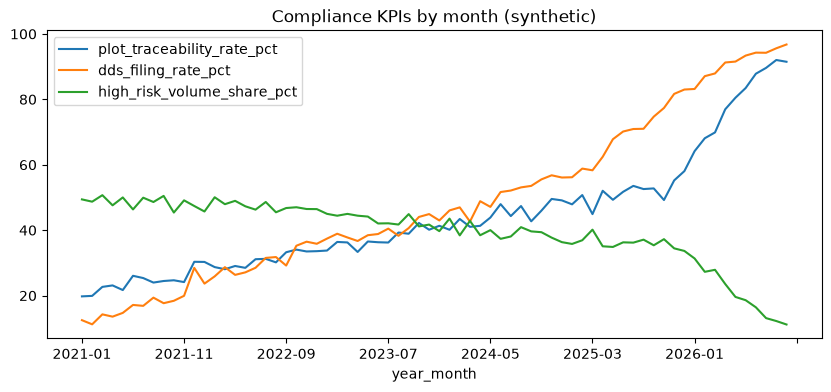

In [12]:
cols = ["plot_traceability_rate_pct", "high_risk_volume_share_pct", "dds_filing_rate_pct", "value_at_risk_eur"]
print(k[cols].iloc[::12].round(1))     # one row per year

k[["plot_traceability_rate_pct", "dds_filing_rate_pct", "high_risk_volume_share_pct"]].plot(figsize=(10, 4), title="Compliance KPIs by month (synthetic)")